# NSGA-II algoritmoa (oinarrizko bertsioa)

**Problema:** bi helburu minimizatu

- $f_1(x_1, x_2) = x_1$
- $f_2(x_1, x_2) = x_2$

**Murriztapenak:**

- $C_1(x_1,x_2) = x_1^2 + x_2^2 - 1 - 0.1\cos\left(16\arctan\frac{x_1}{x_2}\right) \ge 0$
- $C_2(x_1,x_2) = (x_1 - 0.5)^2 + (x_2 - 0.5)^2 \le 0.5$
- $0 \le x_1, x_2 \le \pi$

Soluzio bat bideragarria ez bada, bi helburuei **10** balioa esleitzen zaie.

## 1. Liburutegiak eta parametroak

In [1]:
import math
import random
import matplotlib.pyplot as plt

POP_TAMAINA = 100        # Populazioaren tamaina (N)
BELAUNALDIAK = 200       # Belaunaldi kopurua
GURUTZAKETA_PROB = 0.9   # Gurutzaketa probabilitatea
MUTAZIO_PROB = 0.5       # Mutazio probabilitatea (aldagai bakoitzeko: 1/n, n=2)
ETA_C = 20               # SBX gurutzaketaren banaketa-indizea
ETA_M = 20               # Mutazio polinomialaren banaketa-indizea
BEHE_MUGA = 0.0
GOI_MUGA = math.pi
EZ_BIDERAGARRIA = 10.0   # Soluzio ez bideragarriei esleitzen zaien balioa
HAZIA = 1
COS_KOEF = 0.1          # C1 murriztapeneko cos-aren koefizientea (TNK problema)

ModuleNotFoundError: No module named 'matplotlib'

## 2. Problema: helburu funtzioak eta murriztapenak

`atan2(x1, x2)` erabiltzen da: $x_2 > 0$ denean $\arctan(x_1/x_2)$-ren berdina da, eta $x_2 = 0$ kasuan zatiketa zeroz saihesten du.

In [ ]:
def c1(x1, x2):
    # atan2(x1, x2) = arctan(x1/x2) x2 > 0 denean, eta x2 = 0 kasuan ere ondo dabil
    return x1 ** 2 + x2 ** 2 - 1 - COS_KOEF * math.cos(16 * math.atan2(x1, x2))


def c2(x1, x2):
    return (x1 - 0.5) ** 2 + (x2 - 0.5) ** 2


def bideragarria(x):
    x1, x2 = x
    return c1(x1, x2) >= 0 and c2(x1, x2) <= 0.5


def ebaluatu(x):
    """Helburu funtzioen balioak itzultzen ditu: (f1, f2)."""
    if not bideragarria(x):
        return (EZ_BIDERAGARRIA, EZ_BIDERAGARRIA)
    return (x[0], x[1])

## 3. Dominantzia eta sailkapen ez-menderatua

$a$-k $b$ menderatzen du helburu guztietan $a$ ez bada okerragoa eta gutxienez batean hobea bada. Sailkapen azkarrak (*fast non-dominated sort*) populazioa frontetan banatzen du: 0. frontea = inork menderatzen ez dituenak.

In [ ]:
def menderatzen_du(a, b):
    """True, a-k b menderatzen badu (minimizazioa)."""
    hobea_edo_berdina = all(ai <= bi for ai, bi in zip(a, b))
    hobea_bat = any(ai < bi for ai, bi in zip(a, b))
    return hobea_edo_berdina and hobea_bat


def sailkapen_ez_menderatua(helburuak):
    """
    Fronteen zerrenda itzultzen du; fronte bakoitza indizeen zerrenda bat da.
    Gainera, maila[i] = i soluzioaren frontearen zenbakia (0 = onena).
    """
    n = len(helburuak)
    menderatuak = [[] for _ in range(n)]   # S_p: p-k menderatzen dituenak
    menderatzaile_kop = [0] * n            # n_p: p menderatzen dutenen kopurua
    maila = [0] * n
    fronteak = [[]]

    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if menderatzen_du(helburuak[p], helburuak[q]):
                menderatuak[p].append(q)
            elif menderatzen_du(helburuak[q], helburuak[p]):
                menderatzaile_kop[p] += 1
        if menderatzaile_kop[p] == 0:
            maila[p] = 0
            fronteak[0].append(p)

    i = 0
    while fronteak[i]:
        hurrengoa = []
        for p in fronteak[i]:
            for q in menderatuak[p]:
                menderatzaile_kop[q] -= 1
                if menderatzaile_kop[q] == 0:
                    maila[q] = i + 1
                    hurrengoa.append(q)
        i += 1
        fronteak.append(hurrengoa)

    fronteak.pop()  # azkena hutsik dago
    return fronteak, maila

## 4. Pilaketa-distantzia (crowding distance)

Fronte bereko soluzioen artean, inguruan hutsune handiagoa dutenak lehenesten dira, frontean dibertsitatea mantentzeko. Muturretako soluzioek distantzia infinitua dute.

In [ ]:
def pilaketa_distantzia(fronte, helburuak):
    """Fronte bateko soluzio bakoitzaren pilaketa-distantzia (dict: indizea -> d)."""
    dist = {i: 0.0 for i in fronte}
    if len(fronte) <= 2:
        for i in fronte:
            dist[i] = float("inf")
        return dist

    helburu_kop = len(helburuak[fronte[0]])
    for m in range(helburu_kop):
        ordenatua = sorted(fronte, key=lambda i: helburuak[i][m])
        f_min = helburuak[ordenatua[0]][m]
        f_max = helburuak[ordenatua[-1]][m]
        dist[ordenatua[0]] = float("inf")
        dist[ordenatua[-1]] = float("inf")
        if f_max == f_min:
            continue
        for k in range(1, len(ordenatua) - 1):
            aurrekoa = helburuak[ordenatua[k - 1]][m]
            hurrengoa = helburuak[ordenatua[k + 1]][m]
            dist[ordenatua[k]] += (hurrengoa - aurrekoa) / (f_max - f_min)
    return dist

## 5. Operadore genetikoak

- **Txapelketa bitarra:** maila txikiagoa irabazten du; berdinketan, pilaketa-distantzia handiagoa.
- **SBX gurutzaketa** (*Simulated Binary Crossover*).
- **Mutazio polinomiala.**

In [ ]:
def txapelketa_bitarra(maila, distantzia):
    """Bi indibiduo ausaz hartu eta hoberena itzuli (maila, gero pilaketa-distantzia)."""
    a, b = random.sample(range(len(maila)), 2)
    if maila[a] < maila[b]:
        return a
    if maila[b] < maila[a]:
        return b
    return a if distantzia[a] > distantzia[b] else b


def mugatu(v):
    return min(max(v, BEHE_MUGA), GOI_MUGA)


def sbx_gurutzaketa(g1, g2):
    """Simulated Binary Crossover (SBX)."""
    if random.random() > GURUTZAKETA_PROB:
        return g1[:], g2[:]
    s1, s2 = [], []
    for x1, x2 in zip(g1, g2):
        u = random.random()
        if u <= 0.5:
            beta = (2 * u) ** (1 / (ETA_C + 1))
        else:
            beta = (1 / (2 * (1 - u))) ** (1 / (ETA_C + 1))
        s1.append(mugatu(0.5 * ((1 + beta) * x1 + (1 - beta) * x2)))
        s2.append(mugatu(0.5 * ((1 - beta) * x1 + (1 + beta) * x2)))
    return s1, s2


def mutazio_polinomiala(x):
    """Mutazio polinomiala, aldagai bakoitzean MUTAZIO_PROB probabilitatearekin."""
    y = x[:]
    tartea = GOI_MUGA - BEHE_MUGA
    for i in range(len(y)):
        if random.random() < MUTAZIO_PROB:
            u = random.random()
            if u < 0.5:
                delta = (2 * u) ** (1 / (ETA_M + 1)) - 1
            else:
                delta = 1 - (2 * (1 - u)) ** (1 / (ETA_M + 1))
            y[i] = mugatu(y[i] + delta * tartea)
    return y


def ondorengoak_sortu(populazioa, maila, distantzia):
    """Txapelketa + gurutzaketa + mutazioa erabiliz N ondorengo sortu."""
    ondorengoak = []
    while len(ondorengoak) < POP_TAMAINA:
        g1 = populazioa[txapelketa_bitarra(maila, distantzia)]
        g2 = populazioa[txapelketa_bitarra(maila, distantzia)]
        s1, s2 = sbx_gurutzaketa(g1, g2)
        ondorengoak.append(mutazio_polinomiala(s1))
        if len(ondorengoak) < POP_TAMAINA:
            ondorengoak.append(mutazio_polinomiala(s2))
    return ondorengoak

## 6. Hautaketa

$R = P \cup Q$ (tamaina $2N$) frontetan sailkatu eta fronteak osorik sartzen dira $N$ bete arte. Osorik sartzen ez den azken frontean, pilaketa-distantzia handiena dutenak aukeratzen dira.

In [ ]:
def hautaketa(populazioa, helburuak):
    fronteak, _ = sailkapen_ez_menderatua(helburuak)
    hautatuak = []
    for fronte in fronteak:
        dist = pilaketa_distantzia(fronte, helburuak)
        if len(hautatuak) + len(fronte) <= POP_TAMAINA:
            hautatuak.extend(fronte)
        else:
            # Azken frontea: pilaketa-distantzia handienak dituztenak hartu
            falta = POP_TAMAINA - len(hautatuak)
            ordenatua = sorted(fronte, key=lambda i: dist[i], reverse=True)
            hautatuak.extend(ordenatua[:falta])
            break
    return [populazioa[i] for i in hautatuak], [helburuak[i] for i in hautatuak]


def maila_eta_distantzia(helburuak):
    """Populazio bateko indibiduo bakoitzaren maila eta pilaketa-distantzia."""
    fronteak, maila = sailkapen_ez_menderatua(helburuak)
    distantzia = [0.0] * len(helburuak)
    for fronte in fronteak:
        for i, d in pilaketa_distantzia(fronte, helburuak).items():
            distantzia[i] = d
    return maila, distantzia

## 7. NSGA-II algoritmo nagusia

In [ ]:
def nsga2():
    random.seed(HAZIA)

    # 1. Hasierako populazioa ausaz sortu eta ebaluatu
    P = [[random.uniform(BEHE_MUGA, GOI_MUGA) for _ in range(2)]
         for _ in range(POP_TAMAINA)]
    P_helb = [ebaluatu(x) for x in P]

    for belaunaldia in range(1, BELAUNALDIAK + 1):
        # 2. Maila eta pilaketa-distantzia kalkulatu (txapelketarako)
        maila, distantzia = maila_eta_distantzia(P_helb)

        # 3. Ondorengoak (Q) sortu eta ebaluatu
        Q = ondorengoak_sortu(P, maila, distantzia)
        Q_helb = [ebaluatu(x) for x in Q]

        # 4. R = P ∪ Q elkartu eta hurrengo belaunaldia hautatu
        P, P_helb = hautaketa(P + Q, P_helb + Q_helb)

        if belaunaldia % 20 == 0:
            bider = sum(1 for f in P_helb if f[0] != EZ_BIDERAGARRIA)
            lehen = sum(1 for m in maila_eta_distantzia(P_helb)[0] if m == 0)
            print(f"Belaunaldia {belaunaldia:4d} | bideragarriak: {bider:3d} "
                  f"| lehen frontean: {lehen:3d}")

    # 5. Azken Pareto frontea (lehen fronteko soluzio bideragarriak)
    fronteak, _ = sailkapen_ez_menderatua(P_helb)
    pareto = [(P[i], P_helb[i]) for i in fronteak[0]
              if P_helb[i][0] != EZ_BIDERAGARRIA]
    pareto.sort(key=lambda s: s[1][0])
    return pareto

## 8. Exekuzioa

In [ ]:
pareto = nsga2()
print(f"\nPareto fronteko soluzio kopurua: {len(pareto)}")
for x, f in pareto[:10]:
    print(f"  x = ({x[0]:.4f}, {x[1]:.4f})  ->  f = ({f[0]:.4f}, {f[1]:.4f})")
if len(pareto) > 10:
    print("  ...")

Belaunaldia   20 | bideragarriak: 100 | lehen frontean:  89


Belaunaldia   40 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia   60 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia   80 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia  100 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia  120 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia  140 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia  160 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia  180 | bideragarriak: 100 | lehen frontean: 100


Belaunaldia  200 | bideragarriak: 100 | lehen frontean: 100

Pareto fronteko soluzio kopurua: 100
  x = (0.0437, 1.0381)  ->  f = (0.0437, 1.0381)
  x = (0.0437, 1.0381)  ->  f = (0.0437, 1.0381)
  x = (0.0494, 1.0367)  ->  f = (0.0494, 1.0367)
  x = (0.0584, 1.0316)  ->  f = (0.0584, 1.0316)
  x = (0.0732, 1.0220)  ->  f = (0.0732, 1.0220)
  x = (0.0744, 1.0188)  ->  f = (0.0744, 1.0188)
  x = (0.0838, 1.0123)  ->  f = (0.0838, 1.0123)
  x = (0.0949, 1.0095)  ->  f = (0.0949, 1.0095)
  x = (0.1021, 0.9947)  ->  f = (0.1021, 0.9947)
  x = (0.1092, 0.9849)  ->  f = (0.1092, 0.9849)
  ...


## 9. Pareto frontea irudikatu

Grisez, eskualde bideragarria; gorriz, NSGA-II-k lortutako frontea.

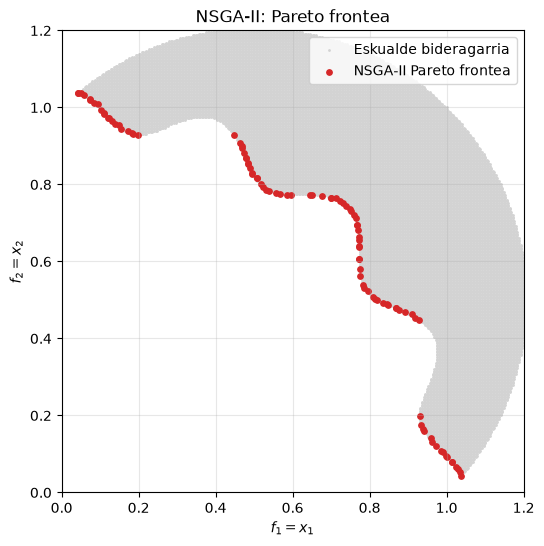

In [ ]:
# Eskualde bideragarria marraztu (sare fin bat ebaluatuz)
sarea = [i * 1.2 / 300 for i in range(301)]
bx, by = [], []
for a in sarea:
    for b in sarea:
        if bideragarria((a, b)):
            bx.append(a)
            by.append(b)

f1 = [s[1][0] for s in pareto]
f2 = [s[1][1] for s in pareto]

plt.figure(figsize=(6, 6))
plt.scatter(bx, by, s=1, c="lightgray", label="Eskualde bideragarria")
plt.scatter(f1, f2, s=15, c="tab:red", label="NSGA-II Pareto frontea")
plt.xlabel("$f_1 = x_1$")
plt.ylabel("$f_2 = x_2$")
plt.xlim(0, 1.2)
plt.ylim(0, 1.2)
plt.gca().set_aspect("equal")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.title("NSGA-II: Pareto frontea")
plt.show()